# Baseline Models: Paper Replication Setup
Owner: Anupama Singh

Replicates the data setup of Shangguan et al., *Scalable Early Childhood Reading Performance Prediction* (NeurIPS 2024):

| Setting | Value |
|---|---|
| Data | `ECRIDataSet.csv` (authors' file) |
| Targets | `RMwidRS_target` (Word Identification), `RMwdaRS_target` (Word Attack) |
| Label rule | 1 if the fall-to-spring gain is above the control group's average gain |
| Features | The paper's 16 variables (Table 3) |
| Rows | Labeled students with no missing values (706) |
| Evaluation | 5-fold cross-validation grouped by school (main) and by student |

Models (my part): Logistic Regression, Decision Tree, Linear Regression and Decision Tree Regressor, plus majority-class and mean-gain reference baselines.

Extension (not in the paper): Lasso logistic regression, linear and RBF SVM, and RBF support vector regression.

## 1. Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.svm import SVC, SVR
from sklearn.metrics import roc_auc_score, accuracy_score, mean_absolute_error, mean_squared_error

# Use the local copy in data/ if present, otherwise download from the ECRI repository
LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
raw = pd.read_csv(f"{src}/ECRIRawData.csv", low_memory=False)
print("Students in ECRIDataSet.csv:", len(df))

Students in ECRIDataSet.csv: 6803


## 2. Build the replication dataset
- Keep labeled students only, and drop rows with any missing feature (the paper excludes them for fine-tuning and evaluation).
- Add the fall-to-spring **gain** for the regression models. Spring scores are used only to build this target, never as features.

In [2]:
FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS",
            "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}

spring = raw[raw["Time"] == 2.0].set_index("StuID")[list(TARGETS.values())].add_suffix("_spring")
data = (df[df["RMwidRS_target"].notna()]
        .dropna(subset=FEATURES)
        .join(spring, on="StuID")
        .reset_index(drop=True))
for score in TARGETS.values():
    data[f"{score}_gain"] = data[f"{score}_spring"] - data[score]

X = data[FEATURES]
print(f"Rows: {len(data)} students | Schools: {data['SchlID'].nunique()} | Features: {len(FEATURES)}")
for name, s in TARGETS.items():
    print(f"{name}: {data[s + '_target'].mean():.1%} labeled 1")

Rows: 706 students | Schools: 42 | Features: 16
Word Identification: 54.2% labeled 1
Word Attack: 58.9% labeled 1


### Check: labels follow the paper's rule
Label = 1 when the gain is above the control group's (`Tx == 0`) average gain. The authors computed that average over all 946 labeled students, before rows with missing features were dropped.

In [3]:
all_labeled = df[df["RMwidRS_target"].notna()].join(spring, on="StuID")
for name, s in TARGETS.items():
    gain = all_labeled[f"{s}_spring"] - all_labeled[s]
    control_avg = gain[all_labeled["Tx"] == 0].mean()
    match = ((gain > control_avg).astype(int) == all_labeled[f"{s}_target"]).mean()
    print(f"{name}: control-group average gain = {control_avg:.2f}, "
          f"rule matches {match:.1%} of {len(all_labeled)} labels")

Word Identification: control-group average gain = 26.32, rule matches 100.0% of 946 labels
Word Attack: control-group average gain = 10.75, rule matches 100.0% of 946 labels


## 3. Define the models
- **Classifiers** predict the 0/1 label.
- **Regressors** predict the gain in points. Their predictions are turned into a 0/1 label with the paper's rule (above the training fold's control-group average), so they also get an accuracy and AUC.
- Settings (tree depth, regularization `C`) are **not** fixed by hand: inside each training fold, an inner 4-fold cross-validation picks the value from `GRID`. The test fold is never used for this choice.
- **Lasso** and **SVM** models are an extension beyond the paper.

In [4]:
MODELS = {
    # name: (kind, builder taking the tuned setting: tree depth or C)
    "Majority class":          ("clf", lambda d: DummyClassifier(strategy="most_frequent")),
    "Logistic Regression":     ("clf", lambda d: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
    "Decision Tree":           ("clf", lambda d: DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=0)),
    "Mean gain":               ("reg", lambda d: DummyRegressor()),
    "Linear Regression":       ("reg", lambda d: make_pipeline(StandardScaler(), LinearRegression())),
    "Decision Tree Regressor": ("reg", lambda d: DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=0)),
    # Extension beyond the paper
    "Lasso Logistic Regression": ("clf", lambda c: make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=c))),
    "SVM (linear)":              ("clf", lambda c: make_pipeline(StandardScaler(), SVC(kernel="linear", C=c, probability=True, random_state=0))),
    "SVM (RBF)":                 ("clf", lambda c: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=c, probability=True, random_state=0))),
    "SVR (RBF)":                 ("reg", lambda c: make_pipeline(StandardScaler(), SVR(kernel="rbf", C=c))),
}
# Values tried for each tuned model (tree depth, or regularization strength C)
GRID = {
    "Decision Tree":             range(2, 9),
    "Decision Tree Regressor":   range(2, 9),
    "Lasso Logistic Regression": [0.01, 0.03, 0.1, 0.3, 1],
    "SVM (linear)":              [0.01, 0.1, 1],
    "SVM (RBF)":                 [0.1, 0.3, 1, 3],
    "SVR (RBF)":                 [0.3, 1, 3, 10],
}
TUNED = set(GRID)


def pick_setting(kind, build, X_tr, y_tr, groups_tr, values):
    """Inner 4-fold CV on the training part only. Best AUC (classifier) or lowest MAE (regressor)."""
    scoring = "roc_auc" if kind == "clf" else "neg_mean_absolute_error"
    scores = {v: cross_val_score(build(v), X_tr, y_tr, cv=GroupKFold(4), groups=groups_tr,
                                 scoring=scoring).mean() for v in values}
    return max(scores, key=scores.get)

## 4. Cross-validation

In [5]:
def run_cv(model_name, score, split):
    kind, build = MODELS[model_name]
    groups = data["SchlID"] if split == "school" else data["StuID"]
    label = data[f"{score}_target"]
    gain = data[f"{score}_gain"]
    y = label if kind == "clf" else gain
    folds = []
    for fold, (tr, te) in enumerate(GroupKFold(5).split(X, y, groups)):
        setting = (pick_setting(kind, build, X.iloc[tr], y.iloc[tr], groups.iloc[tr], GRID[model_name])
                   if model_name in TUNED else None)
        model = build(setting).fit(X.iloc[tr], y.iloc[tr])
        if kind == "clf":
            prob = model.predict_proba(X.iloc[te])[:, 1]
            pred_label, ranking = (prob >= 0.5).astype(int), prob
            mae = rmse = np.nan
        else:
            pred_gain = model.predict(X.iloc[te])
            train_part = data.iloc[tr]
            control_avg = train_part.loc[train_part["Tx"] == 0, f"{score}_gain"].mean()
            pred_label, ranking = (pred_gain > control_avg).astype(int), pred_gain
            mae = mean_absolute_error(gain.iloc[te], pred_gain)
            rmse = mean_squared_error(gain.iloc[te], pred_gain) ** 0.5
        auc = roc_auc_score(label.iloc[te], ranking) if np.ptp(ranking) > 0 else 0.5
        folds.append({"fold": fold, "setting": setting, "AUC": auc,
                      "Accuracy": accuracy_score(label.iloc[te], pred_label), "MAE": mae, "RMSE": rmse})
    return pd.DataFrame(folds)


fold_results = []
for split in ["school", "student"]:
    for target_name, score in TARGETS.items():
        for model_name in MODELS:
            f = run_cv(model_name, score, split)
            fold_results.append(f.assign(split=split, target=target_name, model=model_name))
fold_results = pd.concat(fold_results, ignore_index=True)
print("Done:", len(fold_results), "fold results")

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead o

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

... (112 outputs left out)

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Done: 200 fold results


## 5. Results (mean ± standard deviation over the 5 folds)

In [6]:
def summarize(split):
    part = fold_results[fold_results["split"] == split]
    agg = part.groupby(["target", "model"], sort=False)[["AUC", "Accuracy", "MAE", "RMSE"]].agg(["mean", "std"])
    table = pd.DataFrame(index=agg.index)
    for metric in ["AUC", "Accuracy", "MAE", "RMSE"]:
        m, s = agg[(metric, "mean")], agg[(metric, "std")]
        table[metric] = [f"{a:.3f} ± {b:.3f}" if pd.notna(a) else "–" for a, b in zip(m, s)]
    return table

print("School split (test schools never seen in training)")
summarize("school")

School split (test schools never seen in training)


AUC       Accuracy  \
target              model                                                     
Word Identification Majority class             0.500 ± 0.000  0.543 ± 0.023   
                    Logistic Regression        0.671 ± 0.057  0.640 ± 0.052   
                    Decision Tree              0.653 ± 0.066  0.636 ± 0.053   
                    Mean gain                  0.500 ± 0.000  0.543 ± 0.023   
                    Linear Regression          0.672 ± 0.064  0.644 ± 0.052   
                    Decision Tree Regressor    0.647 ± 0.036  0.646 ± 0.030   
                    Lasso Logistic Regression  0.676 ± 0.058  0.640 ± 0.049   
                    SVM (linear)               0.670 ± 0.056  0.631 ± 0.047   
                    SVM (RBF)                  0.668 ± 0.053  0.633 ± 0.047   
                    SVR (RBF)                  0.679 ± 0.035  0.643 ± 0.019   
Word Attack         Majority class             0.500 ± 0.000  0.589 ± 0.055   
                    Logistic Regression        0.614 ± 0.039  0.611 ± 0.063   
                    Decision Tree              0.556 ± 0.054  0.558 ± 0.034   
                    Mean gain                  0.500 ± 0.000  0.589 ± 0.055   
                    Linear Regression          0.622 ± 0.025  0.604 ± 0.044   
                    Decision Tree Regressor    0.554 ± 0.036  0.585 ± 0.034   
                    Lasso Logistic Regression  0.609 ± 0.034  0.606 ± 0.058   
                    SVM (linear)               0.605 ± 0.046  0.585 ± 0.063   
                    SVM (RBF)                  0.600 ± 0.055  0.588 ± 0.046   
                    SVR (RBF)                  0.614 ± 0.049  0.588 ± 0.048   

                                                         MAE           RMSE  
target              model                                                    
Word Identification Majority class                         –              –  
                    Logistic Regression                    –              –  
                    Decision Tree                          –              –  
                    Mean gain                  7.133 ± 0.478  8.840 ± 0.610  
                    Linear Regression          6.513 ± 0.483  8.221 ± 0.606  
                    Decision Tree Regressor    6.701 ± 0.431  8.459 ± 0.597  
                    Lasso Logistic Regression              –              –  
                    SVM (linear)                           –              –  
                    SVM (RBF)                              –              –  
                    SVR (RBF)                  6.658 ± 0.383  8.321 ± 0.559  
Word Attack         Majority class                         –              –  
                    Logistic Regression                    –              –  
                    Decision Tree                          –              –  
                    Mean gain                  5.937 ± 0.268  7.385 ± 0.330  
                    Linear Regression          5.699 ± 0.278  7.033 ± 0.351  
                    Decision Tree Regressor    5.986 ± 0.158  7.407 ± 0.276  
                    Lasso Logistic Regression              –              –  
                    SVM (linear)                           –              –  
                    SVM (RBF)                              –              –  
                    SVR (RBF)                  5.677 ± 0.237  7.141 ± 0.224

In [7]:
print("Student split (schools can appear in train and test)")
summarize("student")

Student split (schools can appear in train and test)


AUC       Accuracy  \
target              model                                                     
Word Identification Majority class             0.500 ± 0.000  0.543 ± 0.066   
                    Logistic Regression        0.667 ± 0.069  0.637 ± 0.068   
                    Decision Tree              0.636 ± 0.087  0.612 ± 0.071   
                    Mean gain                  0.500 ± 0.000  0.543 ± 0.066   
                    Linear Regression          0.674 ± 0.072  0.649 ± 0.071   
                    Decision Tree Regressor    0.646 ± 0.034  0.662 ± 0.047   
                    Lasso Logistic Regression  0.667 ± 0.069  0.635 ± 0.049   
                    SVM (linear)               0.667 ± 0.077  0.623 ± 0.061   
                    SVM (RBF)                  0.690 ± 0.069  0.637 ± 0.068   
                    SVR (RBF)                  0.694 ± 0.071  0.656 ± 0.079   
Word Attack         Majority class             0.500 ± 0.000  0.589 ± 0.041   
                    Logistic Regression        0.634 ± 0.031  0.616 ± 0.046   
                    Decision Tree              0.597 ± 0.052  0.601 ± 0.068   
                    Mean gain                  0.500 ± 0.000  0.589 ± 0.041   
                    Linear Regression          0.632 ± 0.034  0.602 ± 0.041   
                    Decision Tree Regressor    0.594 ± 0.037  0.609 ± 0.026   
                    Lasso Logistic Regression  0.632 ± 0.031  0.612 ± 0.050   
                    SVM (linear)               0.622 ± 0.028  0.603 ± 0.034   
                    SVM (RBF)                  0.632 ± 0.048  0.623 ± 0.041   
                    SVR (RBF)                  0.642 ± 0.048  0.625 ± 0.052   

                                                         MAE           RMSE  
target              model                                                    
Word Identification Majority class                         –              –  
                    Logistic Regression                    –              –  
                    Decision Tree                          –              –  
                    Mean gain                  7.160 ± 0.416  8.871 ± 0.550  
                    Linear Regression          6.605 ± 0.235  8.280 ± 0.325  
                    Decision Tree Regressor    6.718 ± 0.153  8.463 ± 0.338  
                    Lasso Logistic Regression              –              –  
                    SVM (linear)                           –              –  
                    SVM (RBF)                              –              –  
                    SVR (RBF)                  6.556 ± 0.220  8.241 ± 0.227  
Word Attack         Majority class                         –              –  
                    Logistic Regression                    –              –  
                    Decision Tree                          –              –  
                    Mean gain                  5.941 ± 0.559  7.376 ± 0.696  
                    Linear Regression          5.717 ± 0.553  7.039 ± 0.604  
                    Decision Tree Regressor    5.865 ± 0.659  7.310 ± 0.728  
                    Lasso Logistic Regression              –              –  
                    SVM (linear)                           –              –  
                    SVM (RBF)                              –              –  
                    SVR (RBF)                  5.688 ± 0.608  7.096 ± 0.690

### Settings chosen inside each fold (tree depth or C)

In [8]:
(fold_results[fold_results["model"].isin(TUNED)]
 .pivot_table(index=["split", "target", "model"], columns="fold", values="setting"))

fold                                                     0    1    2    3  \
split   target              model                                           
school  Word Attack         Decision Tree              5.0  8.0  6.0  3.0   
                            Decision Tree Regressor    2.0  2.0  2.0  2.0   
                            Lasso Logistic Regression  1.0  1.0  1.0  1.0   
                            SVM (RBF)                  3.0  1.0  0.1  0.1   
                            SVM (linear)               1.0  1.0  1.0  1.0   
                            SVR (RBF)                  1.0  1.0  1.0  3.0   
        Word Identification Decision Tree              3.0  3.0  3.0  8.0   
                            Decision Tree Regressor    2.0  3.0  4.0  3.0   
                            Lasso Logistic Regression  0.3  0.3  0.3  0.3   
                            SVM (RBF)                  1.0  1.0  0.3  0.3   
                            SVM (linear)               0.1  1.0  0.1  1.0   
                            SVR (RBF)                  3.0  3.0  3.0  3.0   
student Word Attack         Decision Tree              8.0  5.0  4.0  3.0   
                            Decision Tree Regressor    2.0  2.0  2.0  4.0   
                            Lasso Logistic Regression  1.0  1.0  1.0  1.0   
                            SVM (RBF)                  1.0  1.0  0.3  1.0   
                            SVM (linear)               1.0  0.1  0.1  0.1   
                            SVR (RBF)                  3.0  1.0  1.0  3.0   
        Word Identification Decision Tree              6.0  4.0  4.0  5.0   
                            Decision Tree Regressor    2.0  2.0  2.0  2.0   
                            Lasso Logistic Regression  1.0  0.3  0.1  0.3   
                            SVM (RBF)                  1.0  1.0  1.0  1.0   
                            SVM (linear)               0.1  0.1  1.0  0.1   
                            SVR (RBF)                  3.0  3.0  3.0  3.0   

fold                                                      4  
split   target              model                            
school  Word Attack         Decision Tree               3.0  
                            Decision Tree Regressor     2.0  
                            Lasso Logistic Regression   0.3  
                            SVM (RBF)                   3.0  
                            SVM (linear)                1.0  
                            SVR (RBF)                   3.0  
        Word Identification Decision Tree               2.0  
                            Decision Tree Regressor     2.0  
                            Lasso Logistic Regression   0.3  
                            SVM (RBF)                   1.0  
                            SVM (linear)                0.1  
                            SVR (RBF)                  10.0  
student Word Attack         Decision Tree               7.0  
                            Decision Tree Regressor     2.0  
                            Lasso Logistic Regression   1.0  
                            SVM (RBF)                   1.0  
                            SVM (linear)                1.0  
                            SVR (RBF)                   1.0  
        Word Identification Decision Tree               5.0  
                            Decision Tree Regressor     2.0  
                            Lasso Logistic Regression   0.3  
                            SVM (RBF)                   1.0  
                            SVM (linear)                0.1  
                            SVR (RBF)                   3.0

## 6. Comparison with the paper's Logistic Regression
Paper values from Table 1 of Shangguan et al. (2024), all students.

In [9]:
paper = pd.DataFrame([
    ("school",  "Word Identification", 0.6121, 0.6119),
    ("school",  "Word Attack",         0.5591, 0.5923),
    ("student", "Word Identification", 0.6201, 0.6207),
    ("student", "Word Attack",         0.5666, 0.6281),
], columns=["split", "target", "paper_AUC", "paper_Accuracy"])

ours = (fold_results[fold_results["model"] == "Logistic Regression"]
        .groupby(["split", "target"])[["AUC", "Accuracy"]].mean()
        .rename(columns={"AUC": "our_AUC", "Accuracy": "our_Accuracy"}).reset_index())
comparison = paper.merge(ours, on=["split", "target"])
comparison["AUC_difference"] = comparison["our_AUC"] - comparison["paper_AUC"]
comparison.round(3)

,split,target,paper_AUC,paper_Accuracy,our_AUC,our_Accuracy,AUC_difference
0,school,Word Identification,0.612,0.612,0.671,0.640,0.059
1,school,Word Attack,0.559,0.592,0.614,0.611,0.055
2,student,Word Identification,0.620,0.621,0.667,0.637,0.047
3,student,Word Attack,0.567,0.628,0.634,0.616,0.067


Our Logistic Regression is a few points higher than the paper's. The paper does not report its fold assignment, seed or Logistic Regression settings, and fold-to-fold variation here is around ±0.05 AUC, so a difference of this size is expected.

## 7. Which features matter (Logistic Regression, Word Identification)
Coefficients of the standardized features, fitted on all 706 students. Positive = more likely to show high growth.

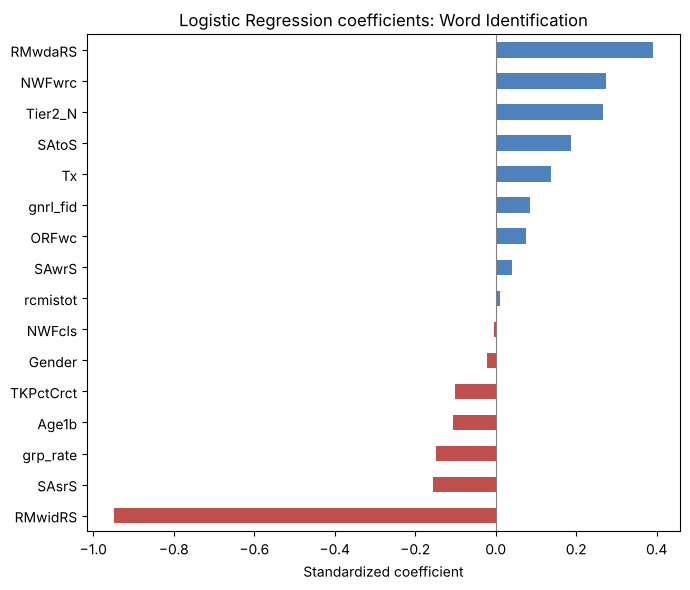

In [10]:
lr = MODELS["Logistic Regression"][1](None).fit(X, data["RMwidRS_target"])
coefs = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()
ax = coefs.plot.barh(figsize=(7, 6), color=["#c0504d" if v < 0 else "#4f81bd" for v in coefs])
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Standardized coefficient")
ax.set_title("Logistic Regression coefficients: Word Identification")
plt.tight_layout()
plt.savefig("../results/replication_logreg_coefficients.png", dpi=150)
plt.show()

## 8. The Decision Tree (Word Identification, depth 3)

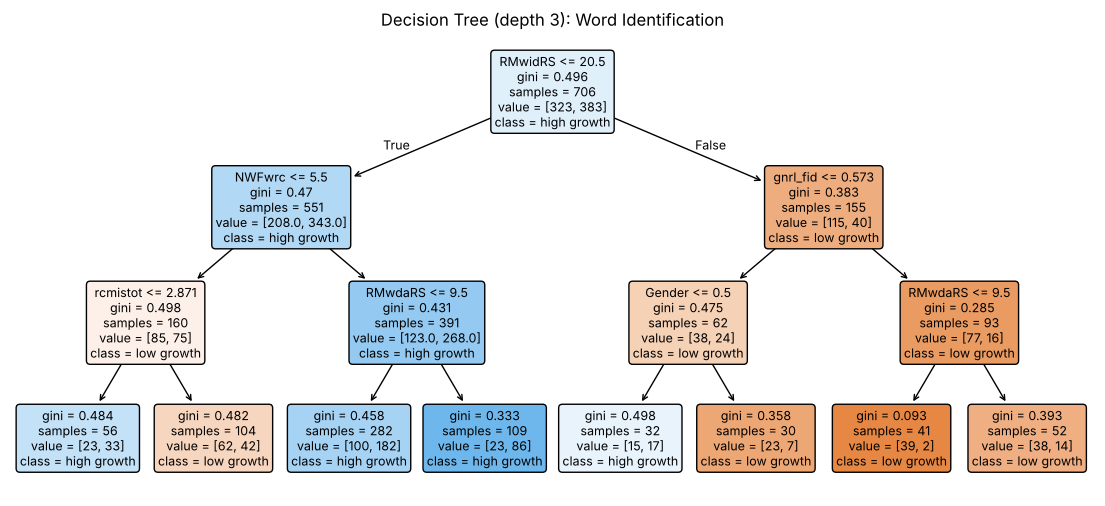

In [11]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(X, data["RMwidRS_target"])
plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=FEATURES, class_names=["low growth", "high growth"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (depth 3): Word Identification")
plt.savefig("../results/replication_decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Save the results

In [12]:
summary = (fold_results.groupby(["split", "target", "model"], sort=False)[["AUC", "Accuracy", "MAE", "RMSE"]]
           .agg(["mean", "std"]).round(4))
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary.reset_index().to_csv("../results/replication_baselines.csv", index=False)
fold_results.to_csv("../results/replication_baselines_folds.csv", index=False)
print("Saved results/replication_baselines.csv and results/replication_baselines_folds.csv")

Saved results/replication_baselines.csv and results/replication_baselines_folds.csv
